<a href="https://colab.research.google.com/github/SMOULD07/calibration_camera/blob/main/calibration_cam%C3%A9ra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Préparation de l'environnement de travail :

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

print("Version OpenCV :", cv2.__version__)
print("Version NumPy :", np.__version__)

Version OpenCV : 4.14.0
Version NumPy : 2.4.6


In [24]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
dossier_images = "/content/drive/MyDrive/calibration_camera_TP01/images_samir"

## Importer mon jeu de données :

In [26]:

# Récupérer les images
images = []

for extension in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
    images.extend(glob.glob(os.path.join(dossier_images, extension)))

# Trier les images
images = sorted(images)

# Afficher le nombre d'images trouvées
print("Nombre d'images trouvées :", len(images))

# Afficher les noms des images
for image in images:
    print(os.path.basename(image))

Nombre d'images trouvées : 31
image_000.png
image_001.png
image_002.png
image_003.png
image_004.png
image_005.png
image_006.png
image_007.png
image_008.png
image_009.png
image_010.png
image_011.png
image_012.png
image_013.png
image_014.png
image_015.png
image_016.png
image_017.png
image_018.png
image_019.png
image_020.png
image_021.png
image_022.png
image_023.png
image_024.png
image_025.png
image_026.png
image_027.png
image_028.png
image_029.png
image_030.png


Suite a un exemple :

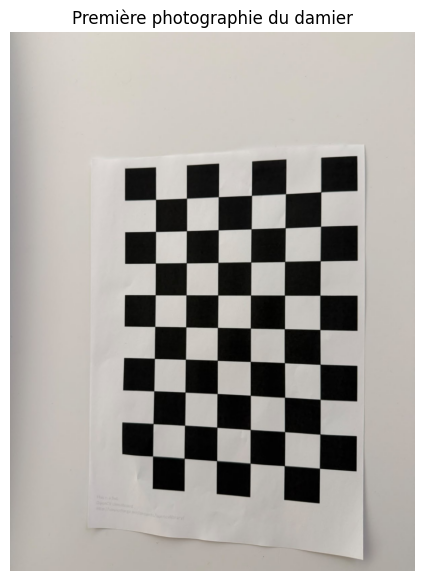

In [27]:

img = cv2.imread(images[0])

# Convertir BGR en RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Afficher l'image
plt.figure(figsize=(10, 7))
plt.imshow(img_rgb)
plt.title("Première photographie du damier")
plt.axis("off")
plt.show()

Dans ce TP de calibration de caméra, nous utilisons un ensemble de photographies d'un damier prises sous différents angles et à différentes positions par rapport à la caméra.

Cette diversité de points de vue est essentielle pour obtenir une calibration fiable. Elle permet à OpenCV d'étudier la projection des points du damier sur le plan image afin d'estimer les paramètres intrinsèques de la caméra ((f_x), (f_y), (c_x), (c_y)) ainsi que les coefficients de distorsion.

**Mon objectif est de comprendre expérimentalement le principe de la calibration et d'analyser les résultats obtenus.**

# Définir les points 3D du damier :

Pour calibrer une caméra, OpenCv a besoin de connaitre 2 infos :
- La position réelle des coins du damier ( dans un repére 3D )
- La position des meme coins dans l'image ( 2D en px )


Le Principe est que OpenCV va comparer ces 2 ensembles de coordonnées pour retrouver les paramétres de la caméra .

Vu que le damier est plat --> tous les coins possédent une coordonnées Z= 0  .
donc si une case = 25 mm ---> P1 = (0,0,0) ; P2 = ( 25, 0, 0 ) ; P3 = ( 50, 0, 0)

In [28]:
import numpy as np

# Nombre de coins intérieurs
chessboard_size = (6, 9)

# Taille réelle d'une case en mètres
taille_case = 0.025  # 2,5 cm

# Création des points 3D
objp = np.zeros((6 * 9, 3), np.float32)

objp[:, :2] = np.mgrid[0:6, 0:9].T.reshape(-1, 2)

# Coordonnées en mètres
objp[:, :2] *= taille_case

print(objp[:10])

[[0.    0.    0.   ]
 [0.025 0.    0.   ]
 [0.05  0.    0.   ]
 [0.075 0.    0.   ]
 [0.1   0.    0.   ]
 [0.125 0.    0.   ]
 [0.    0.025 0.   ]
 [0.025 0.025 0.   ]
 [0.05  0.025 0.   ]
 [0.075 0.025 0.   ]]


## Détection des coins de toute les images :

Le but c'est de retrouver automatiquement les 54 coins intérieurs dans chaque photographie, puis enregistrer leurs coordonnées pour la calibration.

In [29]:
# Stockage des coordonnées 3D et 2D
objpoints = []
imgpoints = []

# Dimensions du damier
chessboard_size = (6, 9)

# Critères pour améliorer la précision des coins
criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    30,
    0.001
)

maintenant avec OpenCV on va utiliser les deux pour paramétres "imgpoints" et "imgpoints" afin calculer les paramètres intrinsèques de notre caméra.

## Détecter les coins de toutes les photographies

In [30]:

# Liste des images correctement détectées
images_valides = []

# Parcourir les photographies
for chemin in images:

    img = cv2.imread(chemin)

    if img is None:
        print("Image illisible :", chemin)
        continue

    # Conversion en niveaux de gris
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Détection des coins
    ret, corners = cv2.findChessboardCorners(
        gray,
        chessboard_size,
        None
    )

    if ret:
        # Amélioration de la précision des coordonnées
        corners2 = cv2.cornerSubPix(
            gray,
            corners,
            (11, 11),
            (-1, -1),
            criteria
        )

        # Sauvegarder les coordonnées 3D
        objpoints.append(objp.copy())

        # Sauvegarder les coordonnées 2D
        imgpoints.append(corners2)

        # Conserver le chemin de l'image valide
        images_valides.append(chemin)

        print("OK :", os.path.basename(chemin))

    else:
        print("ÉCHEC :", os.path.basename(chemin))


OK : image_000.png
OK : image_001.png
OK : image_002.png
OK : image_003.png
OK : image_004.png
OK : image_005.png
OK : image_006.png
OK : image_007.png
OK : image_008.png
OK : image_009.png
OK : image_010.png
OK : image_011.png
OK : image_012.png
OK : image_013.png
OK : image_014.png
OK : image_015.png
OK : image_016.png
OK : image_017.png
OK : image_018.png
OK : image_019.png
OK : image_020.png
OK : image_021.png
OK : image_022.png
OK : image_023.png
OK : image_024.png
OK : image_025.png
OK : image_026.png
OK : image_027.png
OK : image_028.png
OK : image_029.png
OK : image_030.png


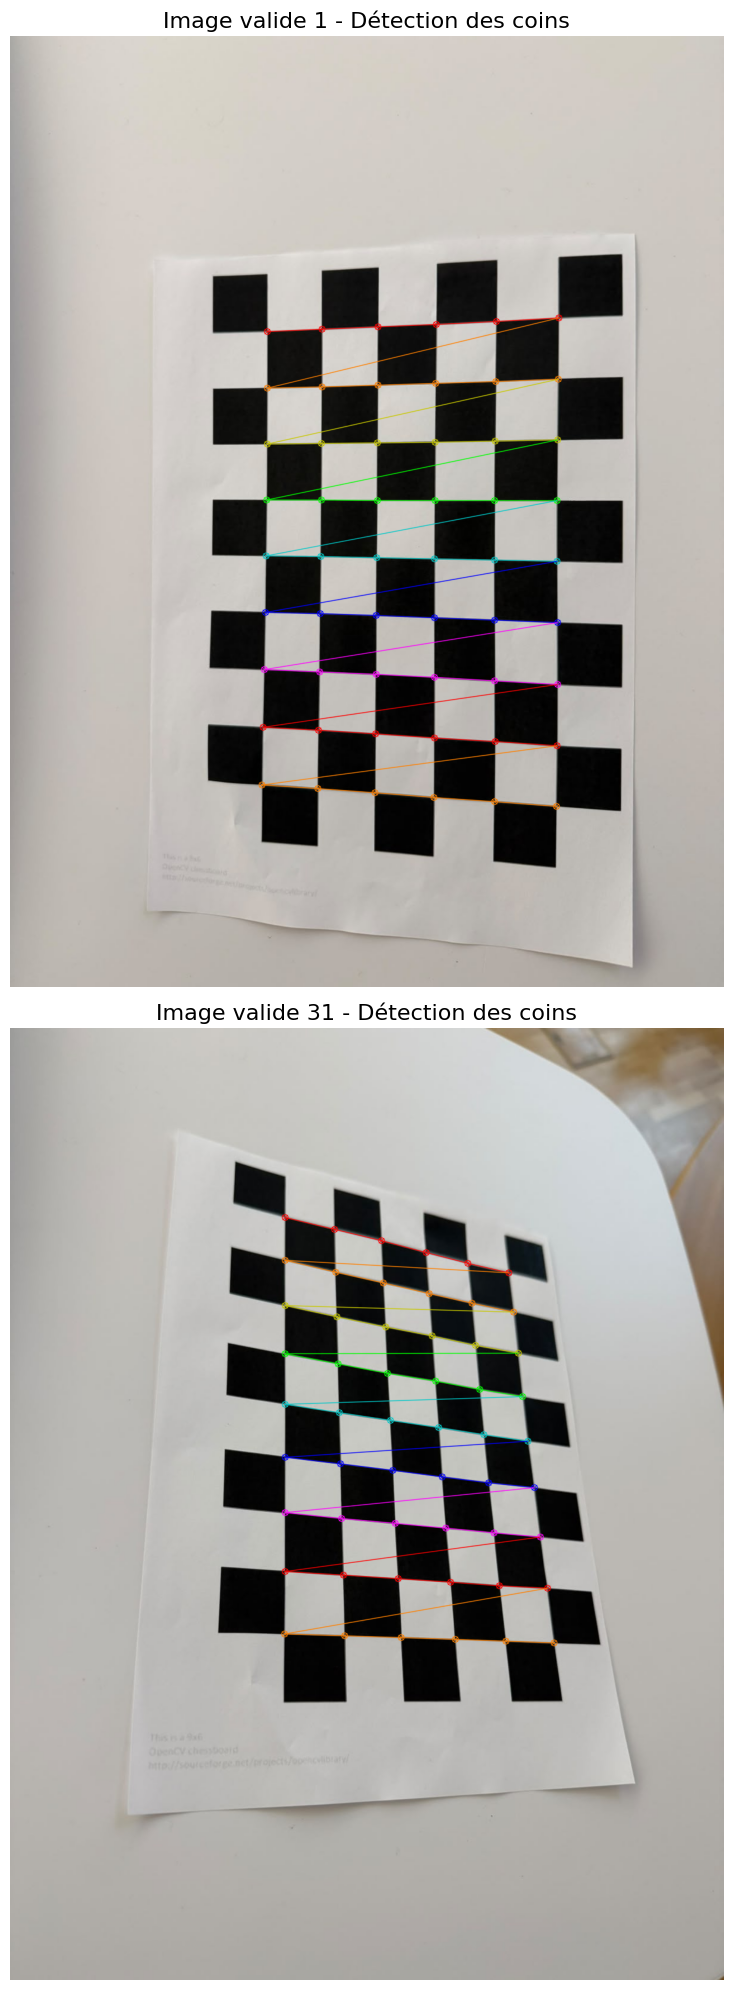

In [31]:

# Sélectionner 2 images réparties dans le jeu de données
indices = [0, len(images_valides) - 1]

# Créer une figure avec 2 images verticales
fig, axes = plt.subplots(2, 1, figsize=(16, 20))

for i, idx in enumerate(indices):

    # Charger l'image
    img = cv2.imread(images_valides[idx])

    # Dessiner les coins détectés
    cv2.drawChessboardCorners(
        img,
        chessboard_size,
        imgpoints[idx],
        True
    )

    # Convertir BGR en RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Afficher l'image
    axes[i].imshow(img_rgb)
    axes[i].set_title(
        f"Image valide {idx + 1} - Détection des coins",
        fontsize=16
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()


Cette étape est importante car elle permet de vérifier que les 54 points caractéristiques du damier (6 × 9) sont correctement localisés avant de procéder à la calibration de la caméra

Le but maintenant c'est de calculer les paramétres intrinséques de notre caméra .

## Vérification de la résolution :

In [32]:
# Vérifier la résolution de toutes les images valides
dimensions = []

for chemin in images_valides:
    img = cv2.imread(chemin)
    hauteur, largeur = img.shape[:2]
    dimensions.append((largeur, hauteur))

resolutions = set(dimensions)

print("Résolutions détectées :", resolutions)

if len(resolutions) != 1:
    raise ValueError(
        "Les images n'ont pas toutes la même résolution."
    )

image_size = dimensions[0]

print("Résolution utilisée :", image_size)

Résolutions détectées : {(1200, 1600)}
Résolution utilisée : (1200, 1600)


In [33]:

# Calibration de la caméra
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints,
    imgpoints,
    image_size,
    None,
    None
)

print("Erreur RMS :", ret)

print("\nMatrice intrinsèque K :")
print(mtx)

print("\nCoefficients de distorsion :")
print(dist)


Erreur RMS : 0.5741767063273681

Matrice intrinsèque K :
[[1.15828585e+03 0.00000000e+00 5.92095996e+02]
 [0.00000000e+00 1.15837713e+03 8.00156144e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

Coefficients de distorsion :
[[ 2.22003737e-01 -8.85866903e-01 -7.18132221e-04 -5.77867755e-04
   8.90001551e-01]]


La calibration a produit une matrice intrinsèque plausible, un point principal proche du centre et une erreur RMS encourageante.

### Analyse des résultats de calibration

La calibration de notre caméra à l'aide de la fonction **cv2.calibrateCamera()** nous a permis d'estimer la matrice intrinsèque ainsi que les coefficients de distorsion.

Les focales obtenues sont \(f_x=1158,29\) pixels et \(f_y=1158,38\) pixels. Leur proximité est cohérente avec l'hypothèse de pixels carrés.

Le point principal estimé est situé aux coordonnées \((592,10\,;\,800,16)\), très proches du centre géométrique de notre image de résolution 1200 × 1600 pixels.

L'erreur RMS de reprojection obtenue est de 0,574 pixel. Cette valeur est encourageante et indique que le modèle reproduit relativement bien les positions des coins détectés.

Les coefficients de distorsion calculés permettent de modéliser les déformations de l'objectif. Une vérification visuelle des images corrigées sera réalisée afin d'évaluer la qualité de la calibration.

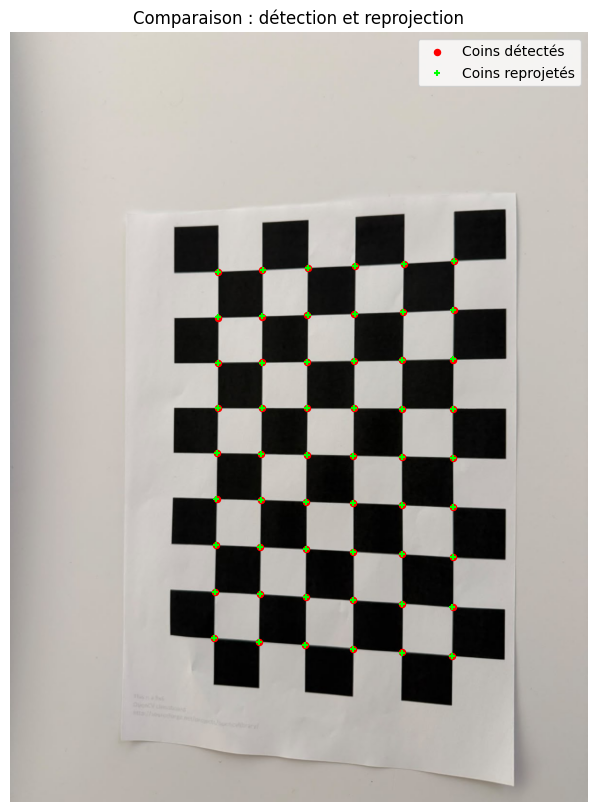

In [36]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Choisir une image valide
idx = 0

# Charger l'image
img = cv2.imread(images_valides[idx])

# Reprojeter les points 3D avec la caméra calibrée
points_projetes, _ = cv2.projectPoints(
    objpoints[idx],
    rvecs[idx],
    tvecs[idx],
    mtx,
    dist
)

# Points réellement détectés
points_detectes = imgpoints[idx].reshape(-1, 2)

# Points prédits par la calibration
points_projetes = points_projetes.reshape(-1, 2)

# Conversion BGR vers RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Affichage
plt.figure(figsize=(12, 10))
plt.imshow(img_rgb)

plt.scatter(
    points_detectes[:, 0],
    points_detectes[:, 1],
    c="red",
    s=15,
    marker="o",
    facecolors="none",
    linewidths=1.5,
    label="Coins détectés"
)

plt.scatter(
    points_projetes[:, 0],
    points_projetes[:, 1],
    c="lime",
    s=15,
    marker="+",
    label="Coins reprojetés"
)

plt.title("Comparaison : détection et reprojection")
plt.legend()
plt.axis("off")
plt.show()


Maintenant que nous avons obtenu la matrice intrinsèque, les coefficients de distorsion et une erreur RMS de 0,574 pixel. Le but maintenant c'est de **corriger la distorsion d'une photographie.**

### Correction des distorsions optiques

Après l'estimation des paramètres intrinsèques et des coefficients de distorsion de la caméra, nous appliquons la fonction `cv2.undistort()` afin de corriger les déformations géométriques présentes dans les photographies.

Nous comparons visuellement une photographie originale avec son image corrigée en utilisant la matrice intrinsèque \(K\) et les coefficients de distorsion calculés précédemment.

Cette étape permet d'observer les effets de la calibration et d'évaluer qualitativement la correction des distorsions optiques.

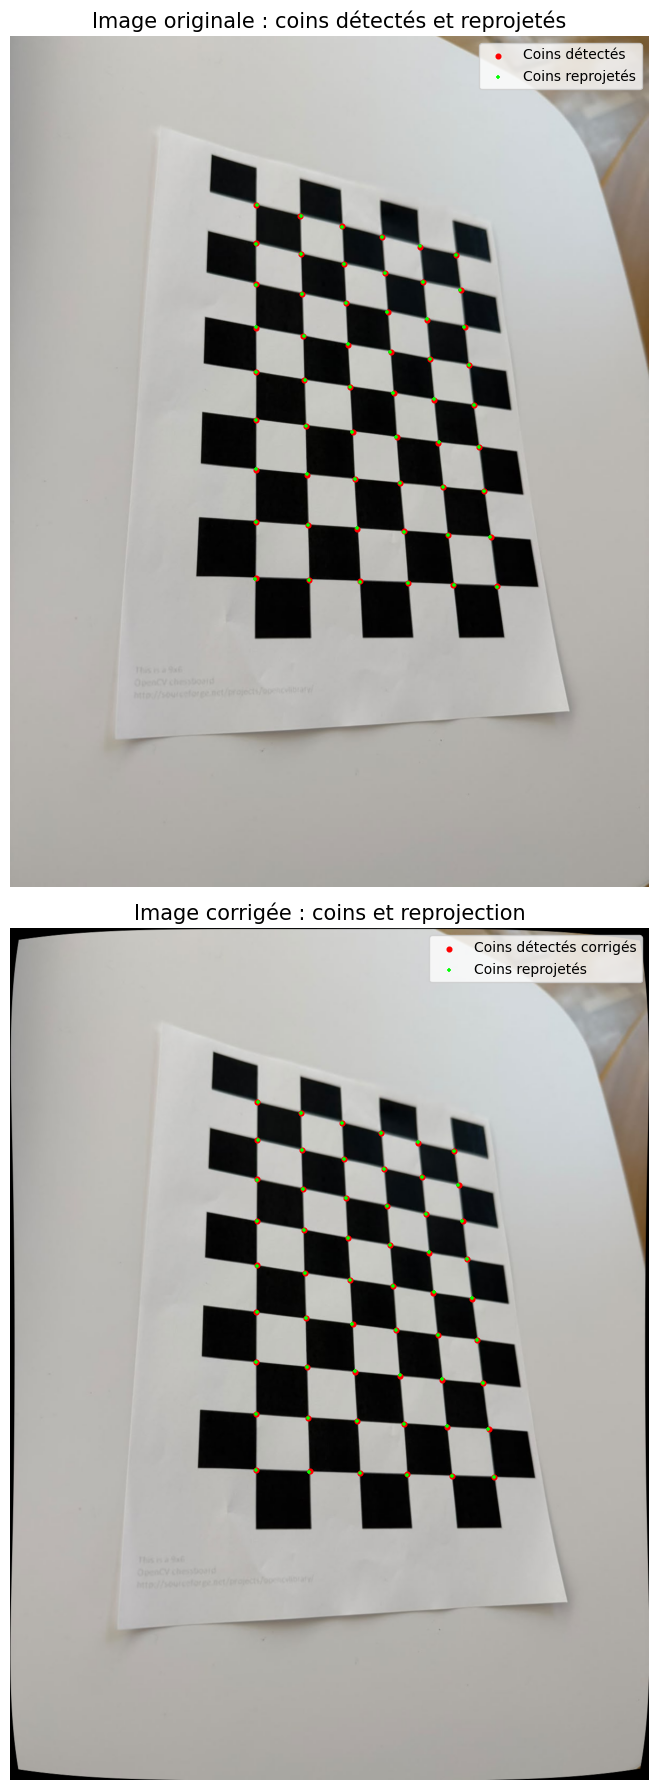

In [44]:

idx = 30

# Charger l'image originale
img = cv2.imread(images_valides[idx])


# Image corrigée
img_corrigee = cv2.undistort(img, mtx, dist, None, mtx)

# ---- 1) Points sur l'image originale ----
# Points détectés
points_detectes = imgpoints[idx].reshape(-1, 2)

# Points reprojetés avec distorsion
points_proj_orig, _ = cv2.projectPoints(
    objpoints[idx],
    rvecs[idx],
    tvecs[idx],
    mtx,
    dist
)
points_proj_orig = points_proj_orig.reshape(-1, 2)

# ---- 2) Points sur l'image corrigée ----
# Coins détectés "corrigés" (undistorted)
points_detectes_corr = cv2.undistortPoints(
    imgpoints[idx],
    mtx,
    dist,
    P=mtx
)
points_detectes_corr = points_detectes_corr.reshape(-1, 2)

# Points reprojetés sur image sans distorsion
points_proj_corr, _ = cv2.projectPoints(
    objpoints[idx],
    rvecs[idx],
    tvecs[idx],
    mtx,
    np.zeros((5, 1))
)
points_proj_corr = points_proj_corr.reshape(-1, 2)

# Conversion en RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_corrigee_rgb = cv2.cvtColor(img_corrigee, cv2.COLOR_BGR2RGB)

# Affichage
fig, axes = plt.subplots(2, 1, figsize=(14, 18))

# Image originale
axes[0].imshow(img_rgb)
axes[0].scatter(
    points_detectes[:, 0],
    points_detectes[:, 1],
    c="red",
    s=10,
    marker="o",
    facecolors="none",
    linewidths=1.2,
    label="Coins détectés"
)
axes[0].scatter(
    points_proj_orig[:, 0],
    points_proj_orig[:, 1],
    c="lime",
    s=10,
    marker="+",
    linewidths=1.2,
    label="Coins reprojetés"
)
axes[0].set_title("Image originale : coins détectés et reprojetés", fontsize=15)
axes[0].legend()
axes[0].axis("off")

# Image corrigée
axes[1].imshow(img_corrigee_rgb)
axes[1].scatter(
    points_detectes_corr[:, 0],
    points_detectes_corr[:, 1],
    c="red",
    s=10,
    marker="o",
    facecolors="none",
    linewidths=1.2,
    label="Coins détectés corrigés"
)
axes[1].scatter(
    points_proj_corr[:, 0],
    points_proj_corr[:, 1],
    c="lime",
    s=10,
    marker="+",
    linewidths=1.2,
    label="Coins reprojetés"
)
axes[1].set_title("Image corrigée : coins et reprojection", fontsize=15)
axes[1].legend()
axes[1].axis("off")

plt.tight_layout()
plt.show()


Sur les deux images, les coins détectés (rouges) et les points reprojetés (verts) sont presque superposés, ce qui indique une bonne cohérence entre les observations et le modèle de caméra estimé.

Nous observons également des modifications géométriques, notamment au niveau des bords de l'image corrigée, où certaines zones noires apparaissent à la suite de la transformation.

L'erreur RMS globale de 0,574 pixel constitue un résultat encourageant. Une analyse complémentaire reste néanmoins nécessaire pour évaluer la fiabilité des paramètres estimés.

# Calculer la focale physique :

In [46]:

# Paramètres de notre calibration
print("Résolution :", image_size)

print("Focale horizontale :", mtx[0, 0], "pixels")
print("Focale verticale :", mtx[1, 1], "pixels")

print("Point principal :", (mtx[0, 2], mtx[1, 2]))


Résolution : (1200, 1600)
Focale horizontale : 1158.28585380192 pixels
Focale verticale : 1158.3771327812908 pixels
Point principal : (np.float64(592.0959964744334), np.float64(800.1561439297692))


In [49]:

# Dimensions du capteur principal (mm)
# Orientation portrait
largeur_capteur_mm = 7.3
hauteur_capteur_mm = 9.8

# Calcul des paramètres physiques
fovx, fovy, focale_mm, principal_point, aspect_ratio = (
    cv2.calibrationMatrixValues(
        mtx,
        image_size,
        largeur_capteur_mm,
        hauteur_capteur_mm
    )
)

# Conversion en mètres
focale_m = focale_mm / 1000

print(f"Focale physique  : {focale_mm:.4f} mm")
print(f"Focale physique : {focale_m:.6f} m")
print(f"Champ de vision horizontal : {fovx:.2f}°")
print(f"Champ de vision vertical : {fovy:.2f}°")
print(f"Point principal physique : {principal_point}")
print(f"Rapport fy/fx : {aspect_ratio:.6f}")


Focale physique  : 7.0462 mm
Focale physique : 0.007046 m
Champ de vision horizontal : 54.77°
Champ de vision vertical : 69.26°
Point principal physique : (3.601917311886136, 4.900956381569836)
Rapport fy/fx : 1.000079


### Analyse des résultats de calibration

La calibration est réalisée sur des images de **1200 × 1600 pixels**. Les focales (f_x=1158,29) et (f_y=1158,38) pixels sont presque identiques, avec un rapport proche de 1.

Le point principal  (592,10 ; 800,16) est proche du centre de l'image, ce qui est cohérent.

La focale physique est estimée à **0,007046 m**, avec des champs de vision de **54,77° horizontalement** et **69,26° verticalement**. Le point principal physique est estimé à **(3,602 ; 4,901) mm**.


# Je souhaite approfondir un peu ce TP et faire une estimation de la pose 3D

L'objectif désormais c'est utiliser notre calibration pour afficher trois axes 3D sur une photographie du damier, comme dans le tutoriel OpenCV .

Rotation :
 [[-0.01679717]
 [ 0.1791847 ]
 [ 0.00628178]]
Translation (m) :
 [[-0.04226718]
 [-0.08002938]
 [ 0.31062688]]


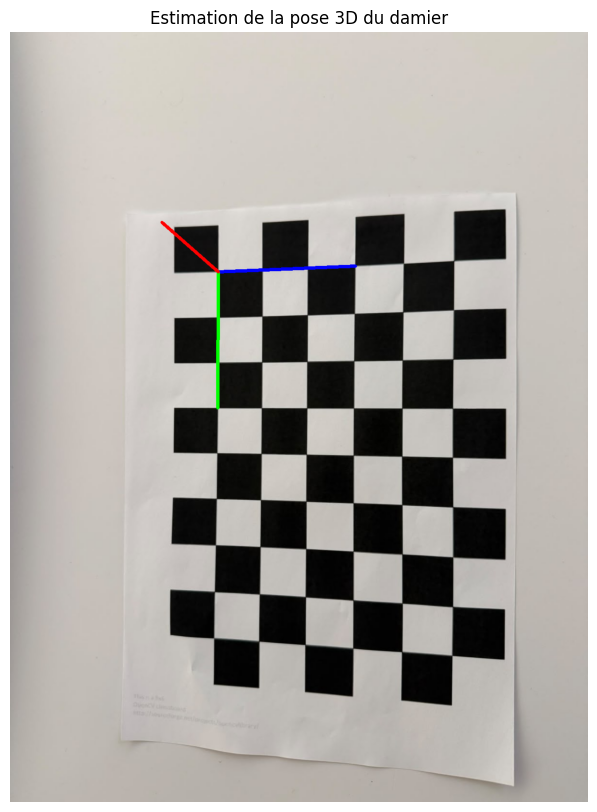

In [50]:


# Choisir une image valide
idx = 0

# Estimation de la pose 3D
success, rvec, tvec = cv2.solvePnP(
    objpoints[idx],
    imgpoints[idx],
    mtx,
    dist
)

if not success:
    raise RuntimeError("Échec de l'estimation de pose")

print("Rotation :\n", rvec)
print("Translation (m) :\n", tvec)

# Définir les axes 3D (3 cases)
L = 3 * taille_case

axis = np.float32([
    [0, 0, 0],
    [L, 0, 0],
    [0, L, 0],
    [0, 0, -L]
])

# Projection des axes dans l'image
imgpts, _ = cv2.projectPoints(
    axis, rvec, tvec, mtx, dist
)

pts = np.round(imgpts.reshape(-1, 2)).astype(int)

# Charger la photographie
img = cv2.imread(images_valides[idx])

# Dessiner les axes X, Y et Z
origine = tuple(pts[0])

cv2.line(img, origine, tuple(pts[1]), (255, 0, 0), 5)
cv2.line(img, origine, tuple(pts[2]), (0, 255, 0), 5)
cv2.line(img, origine, tuple(pts[3]), (0, 0, 255), 5)

# Affichage
plt.figure(figsize=(12, 10))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Estimation de la pose 3D du damier")
plt.axis("off")
plt.show()



Nous utilisons **cv2.solvePnP()** pour estimer la position et l'orientation du damier par rapport à la caméra.

Les axes 3D sont ensuite projetés sur l'image à l'aide de **cv2.projectPoints()**.

 Enfin cette visualisation nous montre comment les paramètres de calibration peuvent être utilisés pour représenter des éléments virtuels dans une scène réelle.